<a href="https://colab.research.google.com/github/GarethH123/Intelligent-Systems-Project/blob/main/Data_Preprocessing_methods.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1.0 Example of Scaling the data

In [3]:
from PIL import Image
import numpy as np
import pandas as pd

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


1.1Get the image

In [5]:
img = Image.open('/content/drive/MyDrive/A.I intellgience info/num 7.jpg')

1.2 Visualse the image

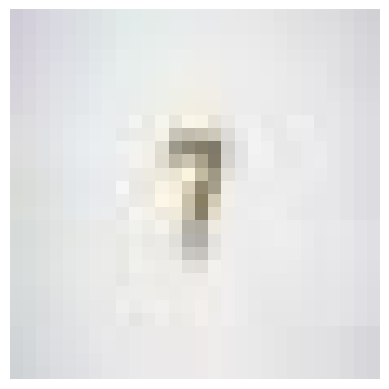

In [6]:
import matplotlib.pyplot as plt

# Display the already loaded image variable 'img'
plt.imshow(img)
plt.axis('off')  # Turn off axis numbers
plt.show()

2.0 Resize the image

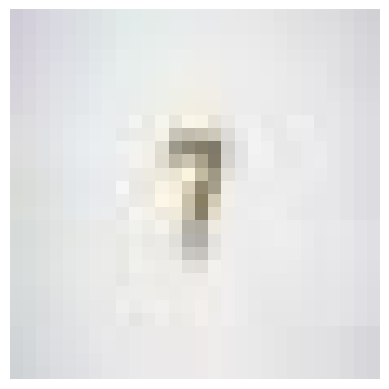

New size: (28, 28)


In [7]:
# Resize the image to 28x28 pixels
resized_img = img.resize((28, 28))

# Display the resized image
plt.imshow(resized_img)
plt.axis('off')
plt.show()

# Verify the new size
print(f"New size: {resized_img.size}")

Method 2

/tmp/ipykernel_2986/3920617105.py:7: FutureWarning: `imshow` is deprecated since version 0.25 and will be removed in version 0.27. Please use `matplotlib`, `napari`, etc. to visualize images.
  io.imshow(image)
/tmp/ipykernel_2986/3920617105.py:8: FutureWarning: `show` is deprecated since version 0.25 and will be removed in version 0.27. Please use `matplotlib`, `napari`, etc. to visualize images.
  io.show()


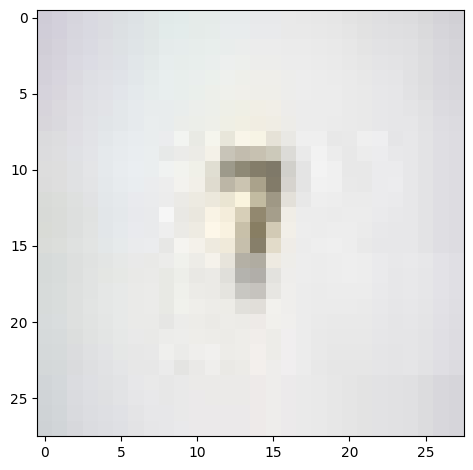

In [8]:
from skimage import io

# Open the image correctly by placing the variable on the left
image = io.imread("/content/drive/MyDrive/A.I intellgience info/num 7.jpg")

# Show the image
io.imshow(image)
io.show()

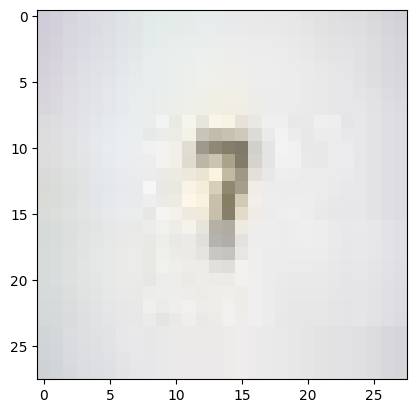

In [9]:
from skimage import io
import matplotlib.pyplot as  plt
# Load the image
image = io.imread("/content/drive/MyDrive/A.I intellgience info/num 7.jpg")
# Display the image
plt.imshow(image)
plt.show()

Display image

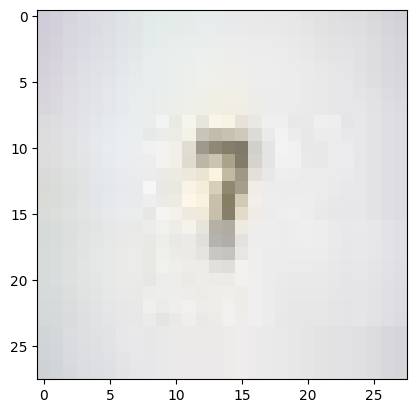

In [10]:
import skimage
from skimage import io, transform
from skimage.util import img_as_ubyte

# Load the image
image = io.imread('/content/drive/MyDrive/A.I intellgience info/num 7.jpg')
resized_image = transform.resize(image, (28, 28))

# Convert the float64 image (0.0 to 1.0) back to uint8 (0 to 255) so it can be saved
resized_image_ubyte = img_as_ubyte(resized_image)

# Save the resized image
io.imsave('/content/drive/MyDrive/A.I intellgience info/num 7.jpg', resized_image_ubyte)

plt.imshow(resized_image_ubyte)
plt.show()


# 3.0 Grayscale

	Procedure
1.	Loop the image’s height and width.
2.	Calculate intensity by the luminosity method for each pixel:
intensity = 0.299×r + 0.587×g + 0.114×b
3.	Set the pixel to the new intensity.


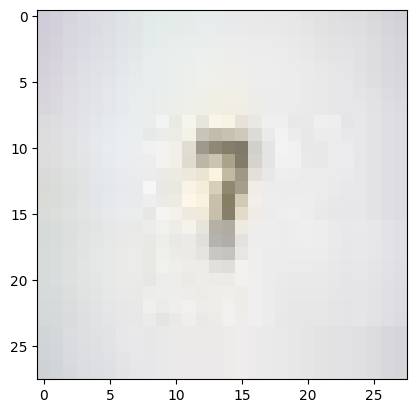

In [11]:
def rgb_to_grayscale(resized_image_ubyte):
  image = resized_image_ubyte.copy()
  for y in range(image.shape[0]):
    for x in range(image.shape[1]):
      value = (0.299 * image[y, x, 0]) + (0.587 * image[y, x, 1]) + (0.114 * image[y, x, 2])
      image[y, x] = value

#call function
rgb_to_grayscale(image)

plt.imshow(image)
plt.show()


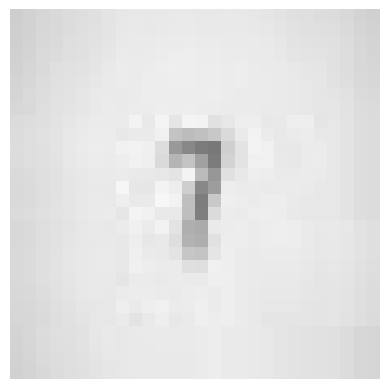

In [12]:
def rgb_to_grayscale(img_array):
  #  copy to avoid overwriting the original image variable
  img_copy = img_array.copy()
  for y in range(img_copy.shape[0]):
    for x in range(img_copy.shape[1]):
      # Luminosity method formula
      value = (0.299 * img_copy[y, x, 0]) + (0.587 * img_copy[y, x, 1]) + (0.114 * img_copy[y, x, 2])
      img_copy[y, x] = value
  return img_copy

# 1. Call the function on the 'image' variable
grayscaled = rgb_to_grayscale(image)

# 2. Display the result using the gray colormap
plt.imshow(grayscaled, cmap='gray')
plt.axis('off')
plt.show()

def rgb_to_grayscale(image): — defines a method taking an argument called image.
for y in range(image.shape[0]): — loop the image’s height
for x in range(image.shape[1]): — loop the image’s width
value = (0.299*image[y,x,0])+(0.587*image[y,x,1])+(0.114*image[y,x,2]) — calculate the new intensity
image[y, x] = value — sets the pixels to the new intensity

# 4.0 Noise reduction

4.1 Model 1 Gausian Blur

In [13]:
import cv2

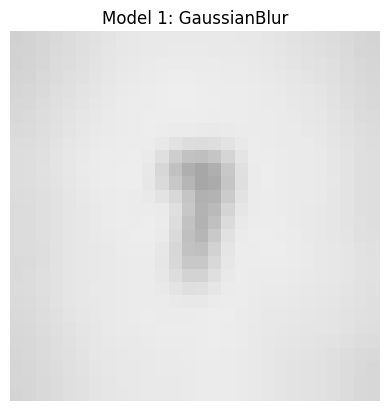

In [14]:
blurred_image = cv2.GaussianBlur(grayscaled, (5, 5), 0)

plt.imshow(blurred_image, cmap='gray')
plt.axis('off')
plt.title('Model 1: GaussianBlur')
plt.show()

\# 4.2 Model 2 medium blur

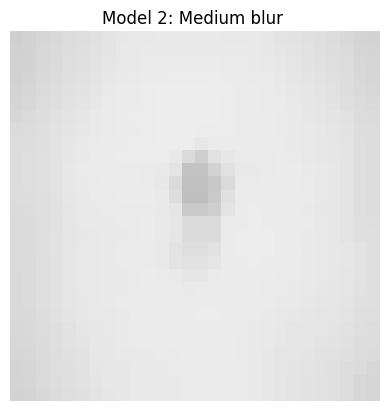

In [15]:
median_blurred_image = cv2.medianBlur(grayscaled, 5)

plt.imshow(median_blurred_image, cmap='gray')
plt.axis('off')
plt.title('Model 2: Medium blur ')
plt.show()

4.3 Model 3

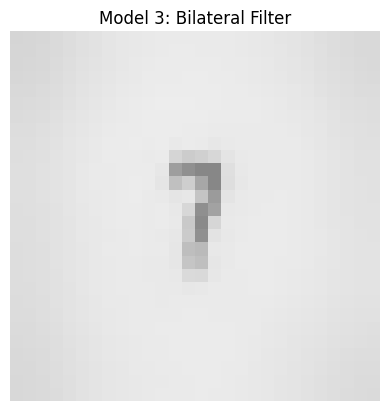

In [16]:
# Model 3: Bilateral Filter (Edge-Preserving Denoising)
bilateral_filtered_image = cv2.bilateralFilter(grayscaled, d=9, sigmaColor=75, sigmaSpace=75)

plt.imshow(bilateral_filtered_image, cmap='gray')
plt.axis('off')
plt.title('Model 3: Bilateral Filter')
plt.show()

5.0 Model Comparison

Calculates the mean square error between the intial gray scaled image to the noise compressed one. the higher the score the better the peformance.

In [17]:
#gt = ground truth
import numpy as np

def PSNR(gt, image, max_value=255):
    """"Function to calculate peak signal-to-noise ratio (PSNR) between two images."""
    # Ensure we use float64 during calculation to prevent overflow issues
    gt = gt.astype(np.float64)
    image = image.astype(np.float64)

    mse = np.mean((gt - image) ** 2)
    if mse == 0:
        return 100
    return 20 * np.log10(max_value / np.sqrt(mse))

# Calculate PSNR using max_value=255 for uint8 images
Model1GausianScore = PSNR(grayscaled, blurred_image, max_value=255)
Model2SaltandPeperScore = PSNR(grayscaled, median_blurred_image, max_value=255)
Model3BilateralScore = PSNR(grayscaled, bilateral_filtered_image, max_value=255)

print("Gaussian Blur PSNR score:", Model1GausianScore)
print("Median Blur PSNR score:", Model2SaltandPeperScore)
print("Bilateral Filter PSNR score:", Model3BilateralScore)

Gaussian Blur PSNR score: 31.837149757515956
Median Blur PSNR score: 27.955200264660277
Bilateral Filter PSNR score: 36.36251133101266
